# 02: Pandas bilan ma'lumotni o'rganish (EDA)
Maqsad: haqiqiy datasetni yuklash, tozalash va model qurishdan oldin tushunib olish.
Dataset: Auto MPG (398 ta mashina)

Mashq 1: Datasetni yuklash va birinchi qarash

📖 Izoh: pandasda ma’lumot DataFrame ko’rinishida saqlanadi. Bu Excel jadvaliga o’xshaydi: qatorlar mashinalarni, ustunlar esa ularning xususiyatlarini bildiradi.

head() → birinchi 5 qator
shape → (qatorlar soni, ustunlar soni)

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("mpg")

print(df.shape)
df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


Mashq 2: Ma’lumot tuzilishi va statistikasi

📖 Izoh:

info() → har bir ustunning turi (son yoki matn) va nechta bo’sh bo’lmagan qiymati borligi
describe() → har bir sonli ustun uchun o’rtacha, minimum, maksimum va boshqa statistikalar

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [13]:
df.describe().round(1)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.0,398.0,398.0,392.0,398.0,398.0,398.0
mean,23.5,5.5,193.4,104.5,2970.4,15.6,76.0
std,7.8,1.7,104.3,38.5,846.8,2.8,3.7
min,9.0,3.0,68.0,46.0,1613.0,8.0,70.0
25%,17.5,4.0,104.2,75.0,2223.8,13.8,73.0
50%,23.0,4.0,148.5,93.5,2803.5,15.5,76.0
75%,29.0,8.0,262.0,126.0,3608.0,17.2,79.0
max,46.6,8.0,455.0,230.0,5140.0,24.8,82.0


Mashq 3: Yo’qolgan qiymatlarni tozalash

📖 Izoh: ML modellari bo’sh qiymatlar (NaN) bilan ishlay olmaydi. Ikkita oddiy yo’l bor: bo’sh qatorlarni o’chirish yoki ularni biror qiymat bilan to’ldirish. 6 ta qator 398 tadan juda kam, shuning uchun ularni o’chiramiz.

In [4]:
print(df.isnull().sum())   # har bir ustunda nechta bo'sh qiymat bor

df = df.dropna()           # bo'sh qiymati bor qatorlarni o'chirish
print(df.shape)

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64
(392, 9)


Mashq 4: Ustunlarni tanlash, filtrlash va guruhlash

📖 Izoh: Bular pandasda eng ko’p ishlatiladigan 3 ta amal:

df[["a", "b"]] → kerakli ustunlarni tanlash
df[shart] → shartga mos qatorlarni tanlash
groupby() → guruhlarga ajratib, statistika hisoblash

In [5]:
# 1. Faqat 3 ta ustun
df[["mpg", "weight", "horsepower"]].head()

,mpg,weight,horsepower
0,18.0,3504,130.0
1,15.0,3693,165.0
2,18.0,3436,150.0
3,16.0,3433,150.0
4,17.0,3449,140.0


In [6]:
# 2. Faqat Yaponiya mashinalari
japan = df[df["origin"] == "japan"]
print(japan.shape)

(79, 9)


In [7]:
# 3. Har bir mamlakat bo'yicha o'rtacha mpg
df.groupby("origin")["mpg"].mean().round(1)

origin
europe    27.6
japan     30.5
usa       20.0
Name: mpg, dtype: float64

Vizualizatsiya va korrelyatsiya

📖 Izoh: Endi eng muhim savolga javob izlaymiz: qaysi feature mpg ni bashorat qilishda eng foydali?

Korrelyatsiya −1 dan +1 gacha bo’lgan son:

−1 ga yaqin → biri oshsa, ikkinchisi kamayadi (kuchli teskari bog’liqlik)
0 ga yaqin → bog’liqlik yo’q
+1 ga yaqin → ikkalasi birga oshadi

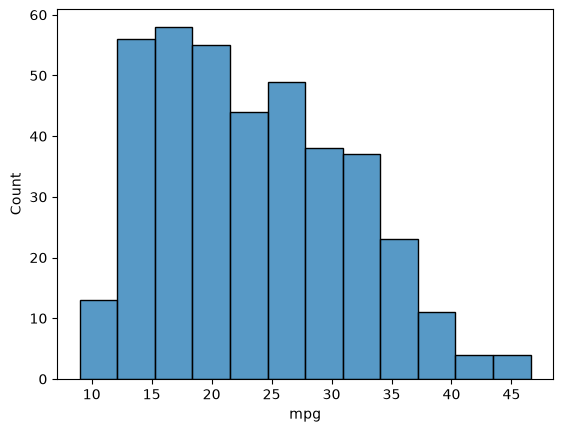

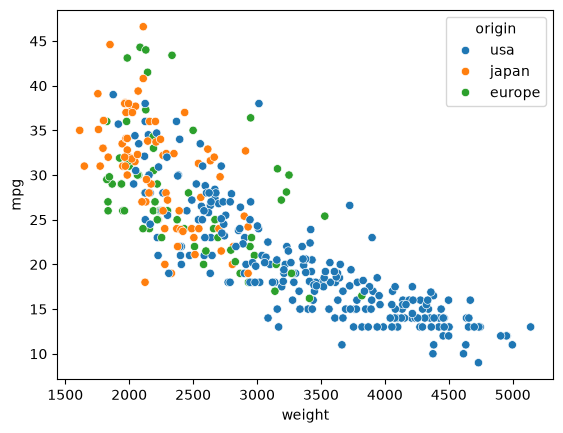

In [8]:
# mpg qanday taqsimlangan
sns.histplot(df["mpg"])
plt.show()

# Og'irlik va mpg, mamlakat bo'yicha ranglangan
sns.scatterplot(data=df, x="weight", y="mpg", hue="origin")
plt.show()

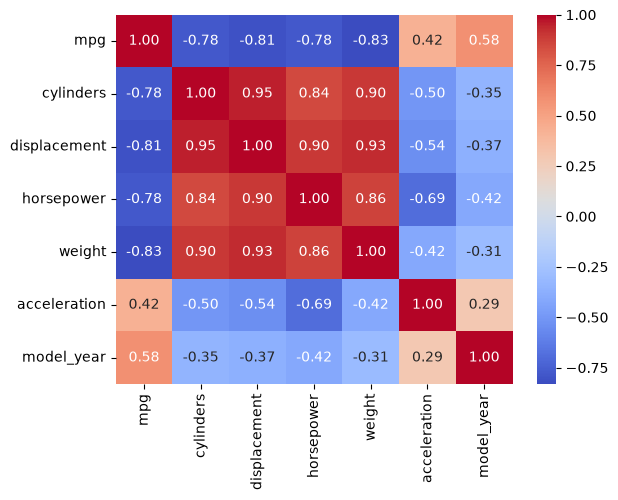

weight         -0.832244
displacement   -0.805127
horsepower     -0.778427
cylinders      -0.777618
acceleration    0.423329
model_year      0.580541
mpg             1.000000
Name: mpg, dtype: float64

In [9]:
# Barcha sonli ustunlar orasidagi korrelyatsiya
corr = df.select_dtypes("number").corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

corr["mpg"].sort_values()